# Video feature classification (classes 0, 1, 2, 3) with a 1D-CNN

Each CSV is one video (one row per frame, OpenFace-style features).
Expected layout:
```
DATA_ROOT/
  train/     0/ 1/ 2/ 3/   (*.csv)
  validate/  0/ 1/ 2/ 3/   (*.csv)
  test/      prediction.csv  +  subfolders with the *.csv files to classify
```

## 1. Imports and configuration (edit paths here)

In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

In [5]:
# ---------------- PATHS ----------------
DATA_ROOT       = r"...\Dataset"
TRAIN_DIR       = os.path.join(DATA_ROOT, "train")
VALIDATE_DIR    = os.path.join(DATA_ROOT, "validate")
TEST_DIR        = os.path.join(DATA_ROOT, "test")
PREDICTION_CSV  = os.path.join(TEST_DIR, "prediction.csv")           # template: id,label
OUTPUT_DIR      = os.path.join(DATA_ROOT, "output")                  # new folder for all results
OUTPUT_CSV      = os.path.join(OUTPUT_DIR, "prediction.csv")         # NEW prediction file (original is not touched)
MODEL_PATH      = os.path.join(OUTPUT_DIR, "best_model.keras")

# ---------------- SETTINGS ----------------
CLASSES         = [0, 1, 2, 3]
DROP_COLUMNS    = ["frame", "face_id", "timestamp", "success"]
MAX_FRAMES      = 300      # each video is padded / cropped to this length
BATCH_SIZE      = 16
EPOCHS          = 60
LEARNING_RATE   = 1e-3
PATIENCE        = 12
SEED            = 42

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

os.makedirs(OUTPUT_DIR, exist_ok=True)
assert os.path.abspath(OUTPUT_CSV) != os.path.abspath(PREDICTION_CSV), "Output must not overwrite the original prediction.csv"

## 2. Load train / validate data
Every video is padded with zeros (or cropped) to `MAX_FRAMES` frames, giving an array of shape `(videos, frames, features)`.

In [7]:
feature_cols = None   # column list is fixed by the first training file

def load_split(folder):
    global feature_cols
    X, y = [], []
    for c in CLASSES:
        files = sorted(glob.glob(os.path.join(folder, str(c), "*.csv")))
        print(f"{os.path.basename(folder):9s} class {c}: {len(files)} files")
        for f in files:
            df = pd.read_csv(f)
            df.columns = df.columns.str.strip()              # OpenFace headers have leading spaces
            if feature_cols is None:
                df = df.drop(columns=[k for k in DROP_COLUMNS if k in df.columns])
                df = df.select_dtypes(include=[np.number])
                feature_cols = list(df.columns)
            else:
                df = df.reindex(columns=feature_cols)         # same columns/order as training
            arr = df.replace([np.inf, -np.inf], np.nan).fillna(0.0).values.astype(np.float32)
            arr = arr[:MAX_FRAMES]                            # crop
            if arr.shape[0] < MAX_FRAMES:                     # pad
                arr = np.vstack([arr, np.zeros((MAX_FRAMES - arr.shape[0], arr.shape[1]), np.float32)])
            X.append(arr); y.append(c)
    assert len(X) > 0, f"No CSV files found in {folder}"
    return np.stack(X), np.array(y)

X_train, y_train = load_split(TRAIN_DIR)
X_val,   y_val   = load_split(VALIDATE_DIR)
print("Train:", X_train.shape, " Validate:", X_val.shape)

train     class 0: 9 files
train     class 1: 9 files
train     class 2: 81 files
train     class 3: 81 files
validate  class 0: 2 files
validate  class 1: 2 files
validate  class 2: 21 files
validate  class 3: 20 files
Train: (180, 300, 670)  Validate: (45, 300, 670)


## 3. Standardise features (training statistics only) and compute class weights

In [11]:
mean = X_train.reshape(-1, X_train.shape[-1]).mean(axis=0)
std  = X_train.reshape(-1, X_train.shape[-1]).std(axis=0)
std[std < 1e-6] = 1.0                                         # constant columns

X_train = (X_train - mean) / std
X_val   = (X_val   - mean) / std

w = compute_class_weight("balanced", classes=np.array(CLASSES), y=y_train)
class_weight = dict(zip(CLASSES, w))
print("Class weights:", class_weight)

Class weights: {0: 5.0, 1: 5.0, 2: 0.5555555555555556, 3: 0.5555555555555556}


## 4. Build the 1D-CNN model

In [25]:
inp = keras.Input(shape=X_train.shape[1:])                    # (frames, features)
x = layers.SpatialDropout1D(0.1)(inp)
x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(len(CLASSES), activation="softmax")(x)

model = keras.Model(inp, out)
model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 300, 670)]        0         
                                                                 
 spatial_dropout1d_1 (Spati  (None, 300, 670)          0         
 alDropout1D)                                                    
                                                                 
 conv1d_3 (Conv1D)           (None, 300, 64)           214464    
                                                                 
 batch_normalization_3 (Bat  (None, 300, 64)           256       
 chNormalization)                                                
                                                                 
 max_pooling1d_2 (MaxPoolin  (None, 150, 64)           0         
 g1D)                                                            
                                                           

## 5. Train

In [28]:
callbacks = [
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", mode="max", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE,
                    class_weight=class_weight, callbacks=callbacks, verbose=2)

Epoch 1/60
12/12 - 2s - loss: 2.0876 - accuracy: 0.2611 - val_loss: 2.3111 - val_accuracy: 0.2667 - lr: 0.0010 - 2s/epoch - 178ms/step
Epoch 2/60
12/12 - 1s - loss: 2.2548 - accuracy: 0.2611 - val_loss: 2.4770 - val_accuracy: 0.2889 - lr: 0.0010 - 506ms/epoch - 42ms/step
Epoch 3/60
12/12 - 0s - loss: 1.8255 - accuracy: 0.2667 - val_loss: 2.1521 - val_accuracy: 0.2889 - lr: 0.0010 - 409ms/epoch - 34ms/step
Epoch 4/60
12/12 - 0s - loss: 1.7045 - accuracy: 0.3056 - val_loss: 1.7445 - val_accuracy: 0.2667 - lr: 0.0010 - 402ms/epoch - 34ms/step
Epoch 5/60
12/12 - 0s - loss: 1.7451 - accuracy: 0.3167 - val_loss: 1.4553 - val_accuracy: 0.2444 - lr: 0.0010 - 393ms/epoch - 33ms/step
Epoch 6/60
12/12 - 0s - loss: 1.6722 - accuracy: 0.2500 - val_loss: 1.3645 - val_accuracy: 0.3556 - lr: 0.0010 - 461ms/epoch - 38ms/step
Epoch 7/60
12/12 - 0s - loss: 2.1302 - accuracy: 0.2500 - val_loss: 1.6728 - val_accuracy: 0.2667 - lr: 0.0010 - 393ms/epoch - 33ms/step
Epoch 8/60
12/12 - 0s - loss: 1.3254 - accu

## 6. Evaluate on the validation set

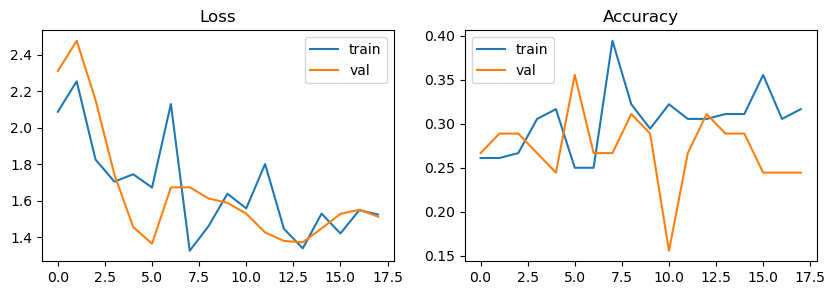

Validation accuracy: 0.3556
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.14      0.50      0.22         2
           2       0.50      0.33      0.40        21
           3       0.53      0.40      0.46        20

    accuracy                           0.36        45
   macro avg       0.29      0.31      0.27        45
weighted avg       0.48      0.36      0.40        45

Confusion matrix (rows = true, cols = predicted):
[[0 0 2 0]
 [0 1 1 0]
 [4 3 7 7]
 [5 3 4 8]]


In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
print("Validation accuracy: %.4f" % (val_pred == y_val).mean())
print(classification_report(y_val, val_pred, labels=CLASSES, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted):")
print(confusion_matrix(y_val, val_pred, labels=CLASSES))

## 7. Classify the test files and fill `prediction.csv`
Test CSV file names (without `.csv`) are matched to the `id` column of the original `prediction.csv`, which is only read. The labels are saved as a **new** `prediction.csv` in `OUTPUT_DIR`.

In [34]:
files = sorted(glob.glob(os.path.join(TEST_DIR, "**", "*.csv"), recursive=True))
files = [f for f in files if os.path.basename(f).lower() != "prediction.csv"]
print(len(files), "test files found")

X_test, stems = [], []
for f in files:
    df = pd.read_csv(f)
    df.columns = df.columns.str.strip()
    df = df.reindex(columns=feature_cols)
    arr = df.replace([np.inf, -np.inf], np.nan).fillna(0.0).values.astype(np.float32)[:MAX_FRAMES]
    if arr.shape[0] < MAX_FRAMES:
        arr = np.vstack([arr, np.zeros((MAX_FRAMES - arr.shape[0], arr.shape[1]), np.float32)])
    X_test.append(arr)
    stems.append(os.path.splitext(os.path.basename(f))[0])
X_test = (np.stack(X_test) - mean) / std

test_pred = model.predict(X_test, verbose=0).argmax(axis=1)
label_of = {}
for s, p in zip(stems, test_pred):
    label_of[s] = int(p)
    if s.isdigit():
        label_of[str(int(s))] = int(p)                        # tolerate leading zeros

result = pd.read_csv(PREDICTION_CSV, dtype={"id": str})
result["id"] = result["id"].str.strip()
result["label"] = [label_of.get(i, label_of.get(str(int(i))) if i.isdigit() else None) for i in result["id"]]

missing = result["label"].isna().sum()
if missing:
    print(f"WARNING: {missing} ids have no matching CSV:", result.loc[result["label"].isna(), "id"].tolist())

result["label"] = result["label"].astype("Int64")
result.to_csv(OUTPUT_CSV, index=False)
print("Saved:", OUTPUT_CSV)
result.head(10)

76 test files found
Saved: D:\Tasneem\Research\2- Ph.D\3- Paper1\DAiSEE_Competition\Dataset\output\prediction.csv


,id,label
0,5100342022,3
1,5100351022,3
2,8264120240,2
3,9877360133,2
4,5100351001,2
5,5100401023,1
6,5100452016,3
7,5100472058,3
8,5000441044,3
9,5000671009,0
